In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import joblib

from pathlib import Path
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [20]:
DATA_PATH = Path("../data/processed")

train_df = pd.read_csv(DATA_PATH / "train.csv")
val_df = pd.read_csv(DATA_PATH / "validation.csv")
test_df = pd.read_csv(DATA_PATH / "test.csv")

print(train_df.shape, val_df.shape, test_df.shape)

(2107, 18) (452, 18) (452, 18)


In [21]:
def prepare_data(data):
    data = data.copy()

    data["Open_Rel"] = data["Open"] / data["Close"] - 1
    data["High_Rel"] = data["High"] / data["Close"] - 1
    data["Low_Rel"] = data["Low"] / data["Close"] - 1
    data["SMA7_Rel"] = data["SMA_7"] / data["Close"] - 1

    return data

train_df = prepare_data(train_df)
val_df = prepare_data(val_df)
test_df = prepare_data(test_df)

print(train_df[["Open_Rel", "High_Rel", "Low_Rel", "SMA7_Rel"]].head())

   Open_Rel  High_Rel   Low_Rel  SMA7_Rel
0  0.038377  0.057736 -0.029208 -0.078593
1  0.013946  0.026421 -0.030886 -0.045448
2 -0.022817  0.004778 -0.041084 -0.042992
3 -0.019547  0.013847 -0.021015 -0.041387
4  0.008369  0.008713 -0.021008 -0.021938


In [22]:
LSTM_FEATURES = [
    "Open_Rel",
    "High_Rel",
    "Low_Rel",
    "Return",
    "Volatility_7",
    "SMA7_Rel",
    "Volume_Change"
]

X_train = train_df[LSTM_FEATURES]
X_val = val_df[LSTM_FEATURES]
X_test = test_df[LSTM_FEATURES]

y_train = train_df["Target"] / train_df["Close"] - 1
y_val = val_df["Target"] / val_df["Close"] - 1
y_test = test_df["Target"] / test_df["Close"] - 1

print("Features:", len(LSTM_FEATURES))
print("Target: Next-day percentage return")

Features: 7
Target: Next-day percentage return


In [24]:
print("Train infinite values:")
print(np.isinf(X_train.to_numpy()).sum(axis=0))

print("\nTrain missing values:")
print(X_train.isnull().sum())

print("\nValidation infinite values:")
print(np.isinf(X_val.to_numpy()).sum(axis=0))

print("\nTest infinite values:")
print(np.isinf(X_test.to_numpy()).sum(axis=0))

Train infinite values:
[0 0 0 0 0 0 1]

Train missing values:
Open_Rel         0
High_Rel         0
Low_Rel          0
Return           0
Volatility_7     0
SMA7_Rel         0
Volume_Change    0
dtype: int64

Validation infinite values:
[0 0 0 0 0 0 0]

Test infinite values:
[0 0 0 0 0 0 0]


In [25]:
# Replace infinity with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Fill missing feature values using training medians
medians = X_train.median()

X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

print("Remaining missing values:", X_train.isnull().sum().sum())
print("Remaining infinite values:", np.isinf(X_train.to_numpy()).sum())

Remaining missing values: 0
Remaining infinite values: 0


In [26]:
X_scaler = MinMaxScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_val_scaled = X_scaler.transform(X_val)
X_test_scaled = X_scaler.transform(X_test)

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).flatten()

y_val_scaled = y_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
).flatten()

y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
).flatten()

print(X_train_scaled.shape)

(2107, 7)


In [27]:
LOOKBACK = 30

def create_sequences(features, targets, lookback=30, context=None):
    if context is None:
        combined = features
        start = lookback - 1
    else:
        combined = np.concatenate([context, features], axis=0)
        start = len(context)

    X, y = [], []

    for i in range(start, len(combined)):
        X.append(combined[i - lookback + 1:i + 1])

        if context is None:
            y.append(targets[i])
        else:
            y.append(targets[i - len(context)])

    return np.array(X), np.array(y)


X_train_seq, y_train_seq = create_sequences(
    X_train_scaled, y_train_scaled, LOOKBACK
)

X_val_seq, y_val_seq = create_sequences(
    X_val_scaled, y_val_scaled, LOOKBACK,
    context=X_train_scaled[-(LOOKBACK - 1):]
)

X_test_seq, y_test_seq = create_sequences(
    X_test_scaled, y_test_scaled, LOOKBACK,
    context=X_val_scaled[-(LOOKBACK - 1):]
)

print("Train:", X_train_seq.shape, y_train_seq.shape)
print("Validation:", X_val_seq.shape, y_val_seq.shape)
print("Test:", X_test_seq.shape, y_test_seq.shape)

Train: (2078, 30, 7) (2078,)
Validation: (452, 30, 7) (452,)
Test: (452, 30, 7) (452,)


In [28]:
model = Sequential([
    Input(shape=(LOOKBACK, len(LSTM_FEATURES))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

start_time = time.time()

history = model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

training_time = time.time() - start_time

print("Training time:", round(training_time, 2), "seconds")
print("Epochs completed:", len(history.history["loss"]))

Epoch 1/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 1.0018 - mae: 0.6467 - val_loss: 0.9377 - val_mae: 0.5952
Epoch 2/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.9973 - mae: 0.6450 - val_loss: 0.9294 - val_mae: 0.5944
Epoch 3/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.9983 - mae: 0.6454 - val_loss: 0.9321 - val_mae: 0.5939
Epoch 4/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.9974 - mae: 0.6449 - val_loss: 0.9280 - val_mae: 0.5945
Epoch 5/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.9960 - mae: 0.6447 - val_loss: 0.9293 - val_mae: 0.5944
Epoch 6/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.9959 - mae: 0.6446 - val_loss: 0.9289 - val_mae: 0.5946
Epoch 7/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.9960 - mae: 0.6447 - val_loss: 0.9299 - val_mae: 0.5941
Epoch 8/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.9967 - mae: 0.6449 - val_loss: 0.9302 - val_mae: 0.5940
Epoch 9/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - lo

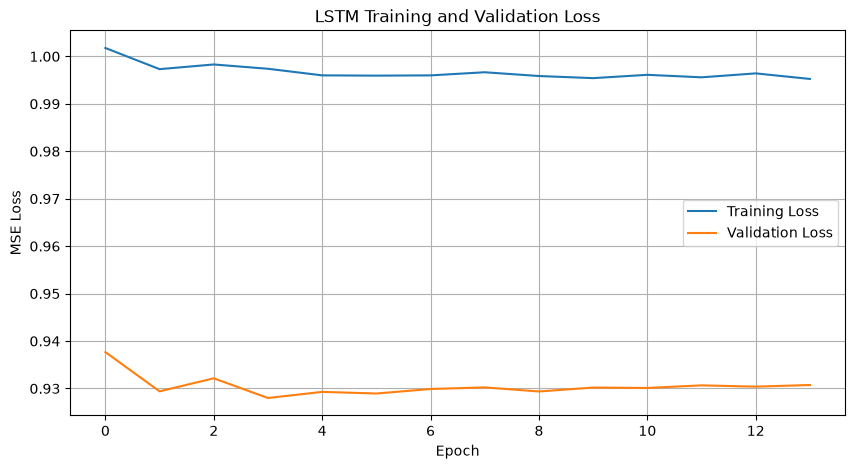

In [30]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
pred_scaled = model.predict(X_test_seq, verbose=0)

pred_return = y_scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).flatten()

y_pred = test_df["Close"].to_numpy() * (1 + pred_return)
y_actual = test_df["Target"].to_numpy()

print("Actual prices:", y_actual[:5])
print("Predicted prices:", y_pred[:5])

Actual prices: [40254.54649816 38356.43950662 35566.65594049 37316.35939997
 39187.32812109]
Predicted prices: [40930.68941691 40386.0840994  38482.72583478 35685.32582387
 37440.88949663]


In [32]:
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mape = np.mean(np.abs((y_actual - y_pred) / y_actual)) * 100
r2 = r2_score(y_actual, y_pred)

print("LSTM Test Results")
print("-----------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"R2:   {r2:.4f}")

LSTM Test Results
-----------------
MAE:  1427.6039
RMSE: 1940.6696
MAPE: 3.41%
R2:   0.9705


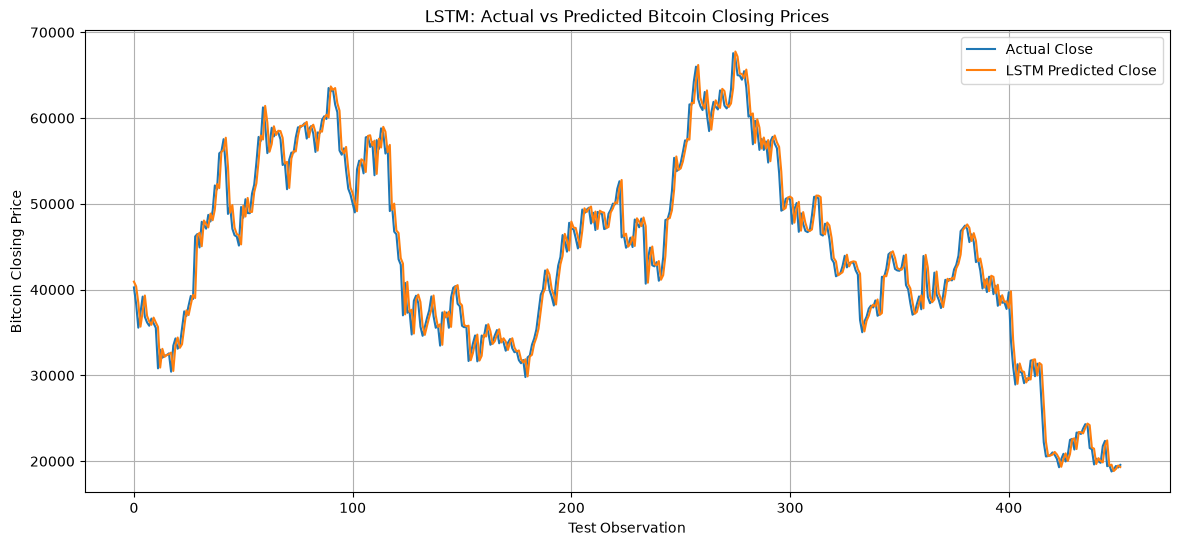

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(y_actual, label="Actual Close")
plt.plot(y_pred, label="LSTM Predicted Close")

plt.xlabel("Test Observation")
plt.ylabel("Bitcoin Closing Price")
plt.title("LSTM: Actual vs Predicted Bitcoin Closing Prices")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../results")

MODEL_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

model.save(MODEL_PATH / "lstm_model.keras")

joblib.dump(X_scaler, MODEL_PATH / "lstm_X_scaler.pkl")
joblib.dump(y_scaler, MODEL_PATH / "lstm_y_scaler.pkl")

predictions_df = pd.DataFrame({
    "Date": test_df["Date"],
    "Actual_Close": y_actual,
    "LSTM_Prediction": y_pred
})

predictions_df.to_csv(
    RESULTS_PATH / "lstm_predictions.csv",
    index=False
)

metrics_df = pd.DataFrame([{
    "Model": "LSTM",
    "MAE": mae,
    "RMSE": rmse,
    "MAPE": mape,
    "R2": r2,
    "Training_Time_Seconds": training_time
}])

metrics_df.to_csv(
    RESULTS_PATH / "lstm_metrics.csv",
    index=False
)

print("LSTM model and results saved successfully.")

LSTM model and results saved successfully.


In [35]:
print("Test rows:", len(test_df))
print("Predictions:", len(y_pred))
print("Missing predictions:", np.isnan(y_pred).sum())

display(predictions_df.head())
display(metrics_df)

Test rows: 452
Predictions: 452
Missing predictions: 0


,Date,Actual_Close,LSTM_Prediction
0,2021-01-08,40254.546498,40930.689417
1,2021-01-09,38356.439507,40386.084099
2,2021-01-10,35566.655940,38482.725835
3,2021-01-11,37316.359400,35685.325824
4,2021-01-13,39187.328121,37440.889497


,Model,MAE,RMSE,MAPE,R2,Training_Time_Seconds
0,LSTM,1427.603866,1940.669603,3.407411,0.970478,15.108693
